# 05 — Spectral resolution, velocity dispersion and convolution

*Lecture 1: stellar populations — how real spectra are made*

A model spectrum is not what a telescope sees. The observed spectrum is

$$F_\mathrm{obs}(\lambda) = \Big[F_\mathrm{model} \ast \mathrm{LOSVD} \ast \mathrm{LSF}\Big] \ \text{sampled on pixels} \ + \ \text{noise}$$

* **LOSVD** — the line-of-sight velocity distribution of the stars (velocity dispersion $\sigma$ of the galaxy),
* **LSF** — the line-spread function of the spectrograph (its resolution, FWHM in Å or $R = \lambda/\Delta\lambda$),
* $\ast$ means **convolution**.

In this notebook you will convolve spectra by hand and see what resolution and velocity dispersion do to absorption lines — and to the line strengths we use to measure ages and metallicities.

FaSTAR spectra come at the resolution of the MILES library: **FWHM = 2.51 Å**, sampled at 0.9 Å per pixel, 3540–7400 Å.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Azeret/stellar-populations-lectures/blob/main/notebooks/05_spectral_resolution.ipynb)  ← run this notebook in your browser, nothing to install

In [1]:
# Running in Google Colab? This cell fetches the course code and installs fastar-astro.
# On your own computer it does nothing.
import sys, os, subprocess
if 'google.colab' in sys.modules:
    if not os.path.isdir('/content/stellar-populations-lectures'):
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/Azeret/stellar-populations-lectures.git',
                        '/content/stellar-populations-lectures'], check=True)
    os.chdir('/content/stellar-populations-lectures/notebooks')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'fastar-astro'], check=True)

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # makes the small 'stellarpops' package importable
import numpy as np
import matplotlib.pyplot as plt
from stellarpops.style import use_slide_style
use_slide_style(dark=False, scale=0.7)       # dark=True gives the lecture-slide look

from fastar import IntegratedSSPSynthesizer, imf
from stellarpops.spectra import (gaussian_kernel, convolve, degrade_resolution, log_rebin,
                                 broaden_velocity, lick_index, add_noise, normalise,
                                 C_KMS, FWHM_FASTAR, SIG2FWHM)

# IntegratedSSPSynthesizer = FaSTAR's model for a whole population (infinitely many stars):
#   it interpolates an isochrone (which stars are alive), weights them with the IMF and adds up
#   their spectra (predicted by a neural network trained on the MILES library). See notebook 02,
#   section 0, for the same calculation done step by step.
ssp = IntegratedSSPSynthesizer(imf_function=imf.kroupa)   # imf.kroupa: Kroupa (2001), 0.1-100 Msun
wave = np.array(ssp.wave)                                 # wavelengths [A], 3540-7410, 0.9 A/pixel
spec = ssp.synthesize(age=10.0, met=0.0)                  # age in Gyr, met = [M/H]; flux per Msun formed
spec = normalise(wave, np.array(spec))                    # divide by the median flux at 5400-5600 A
print(f'{wave.min():.0f}-{wave.max():.0f} A, {np.median(np.diff(wave)):.2f} A per pixel, R = lambda/FWHM = {5000 / FWHM_FASTAR:.0f} at 5000 A')

3540-7410 A, 0.90 A per pixel, R = lambda/FWHM = 1992 at 5000 A


## 1. Convolution by hand

Convolution replaces every pixel by a weighted average of its neighbours; the weights are the **kernel** (here a Gaussian). It spreads each line out but keeps the total flux.

kernel has 51 pixels and sums to 1.0
equivalent width before / after: 6.02 6.02


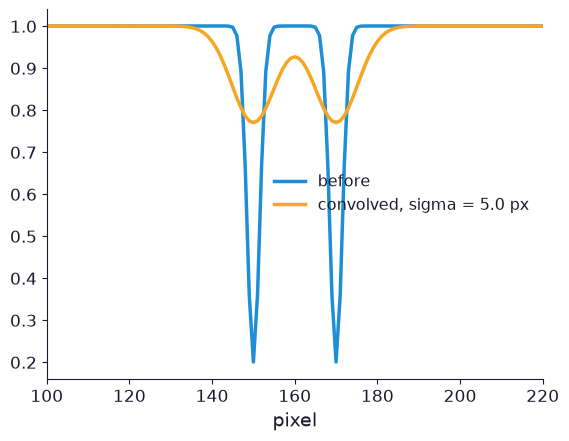

In [3]:
sigma_pix = 5.0                       # kernel width in pixels
k = gaussian_kernel(sigma_pix)
print('kernel has', k.size, 'pixels and sums to', k.sum())

# a fake spectrum: flat continuum with two narrow absorption lines
x = np.arange(400)
toy = 1 - 0.8 * np.exp(-0.5 * ((x - 150) / 1.5) ** 2) - 0.8 * np.exp(-0.5 * ((x - 170) / 1.5) ** 2)
smooth = np.convolve(toy, k, mode='same')

plt.plot(x, toy, label='before'); plt.plot(x, smooth, label=f'convolved, sigma = {sigma_pix} px')
plt.xlim(100, 220); plt.legend(); plt.xlabel('pixel')
print('equivalent width before / after:', round(np.sum(1 - toy), 2), round(np.sum(1 - smooth[20:-20]), 2))

**Question.** The two lines merge into one. How wide (in pixels) must the kernel be for two lines 20 px apart to blend? What stays the same (look at the equivalent width)?

## 2. Instrumental resolution

Gaussians add **in quadrature**: to take a spectrum from FWHM$_\mathrm{in}$ to FWHM$_\mathrm{out}$, convolve with a Gaussian of
$\mathrm{FWHM}_\mathrm{kernel} = \sqrt{\mathrm{FWHM}_\mathrm{out}^2 - \mathrm{FWHM}_\mathrm{in}^2}$.

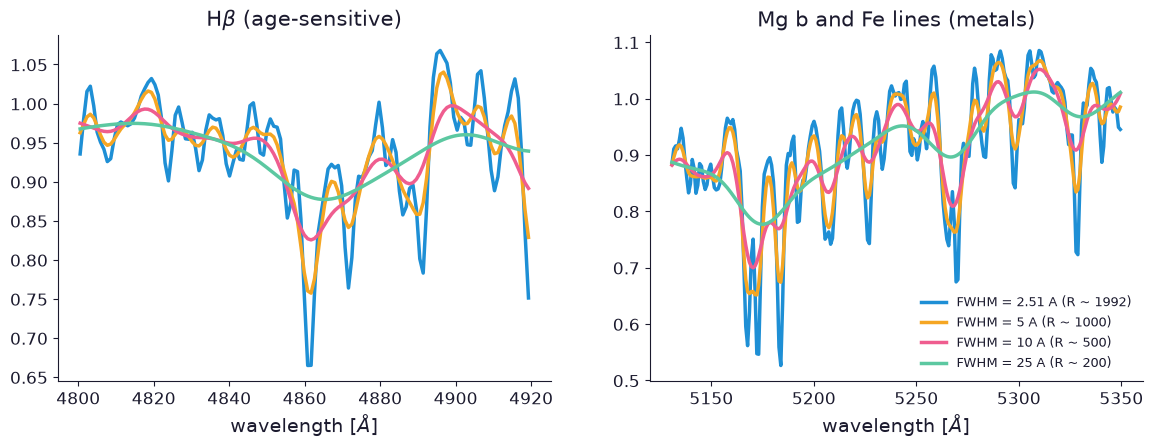

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for fwhm in [FWHM_FASTAR, 5, 10, 25]:
    s = degrade_resolution(wave, spec, FWHM_FASTAR, fwhm)
    for ax, (lo, hi) in zip(axs, [(4800, 4920), (5130, 5350)]):
        sel = (wave > lo) & (wave < hi)
        ax.plot(wave[sel], s[sel], label=f'FWHM = {fwhm:g} A (R ~ {5000 / fwhm:.0f})')
axs[0].set_title(r'H$\beta$ (age-sensitive)'); axs[1].set_title('Mg b and Fe lines (metals)')
for ax in axs: ax.set_xlabel(r'wavelength [$\AA$]')
axs[1].legend(fontsize=9)

For reference: MUSE ~2.5 Å, SDSS ~2.8 Å (R ≈ 2000), a low-resolution prism (e.g. JWST/NIRSpec PRISM) R ~ 100, i.e. FWHM of tens of Å in the optical rest frame.

## 3. Velocity dispersion: why we rebin in ln(λ)

A Doppler shift moves a line by $\Delta\lambda = \lambda\,v/c$: the same velocity spreads a red line more (in Å) than a blue one. If we resample the spectrum onto a grid uniform in $\ln\lambda$, every pixel has the same width in **km/s**,
$\Delta v = c\,\Delta\ln\lambda$ (`velscale`), and the LOSVD becomes one fixed kernel.

velscale = 36.4 km/s per pixel
sigma = 200 km/s at 5175 A corresponds to FWHM = 8.1 A


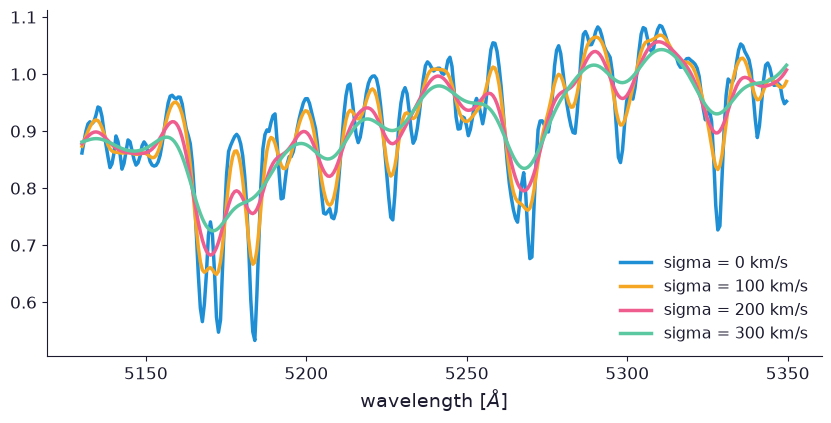

In [5]:
ln_lam, spec_log, velscale = log_rebin(wave, spec)
lam = np.exp(ln_lam)
print(f'velscale = {velscale:.1f} km/s per pixel')

fig, ax = plt.subplots(figsize=(10, 4.5))
sel = (lam > 5130) & (lam < 5350)
for sigma in [0, 100, 200, 300]:
    ax.plot(lam[sel], broaden_velocity(spec_log, velscale, sigma)[sel], label=f'sigma = {sigma} km/s')
ax.legend(); ax.set_xlabel(r'wavelength [$\AA$]')
print('sigma = 200 km/s at 5175 A corresponds to FWHM =', round(SIG2FWHM * 200 / C_KMS * 5175, 1), 'A')

**Question.** A giant elliptical has $\sigma \approx 300$ km/s, a dwarf galaxy 20 km/s. Which one limits the resolution you need: the galaxy or the spectrograph?

## 4. Line strengths depend on σ

Lick indices measure the equivalent width in a fixed window. If the line is broadened, part of it leaks out of the window: the index **drops** although the stars are the same. Index–σ corrections are needed before comparing galaxies.

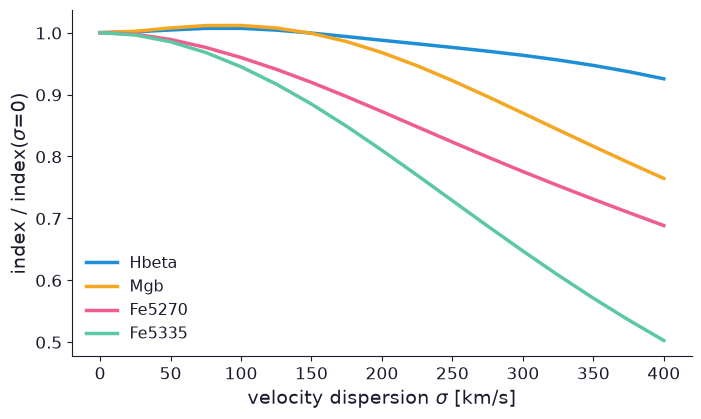

In [6]:
sigmas = np.arange(0, 401, 25)
fig, ax = plt.subplots(figsize=(8, 4.5))
for name in ['Hbeta', 'Mgb', 'Fe5270', 'Fe5335']:
    idx = [lick_index(lam, broaden_velocity(spec_log, velscale, s), name) for s in sigmas]
    ax.plot(sigmas, np.array(idx) / idx[0], label=name)
ax.set_xlabel(r'velocity dispersion $\sigma$ [km/s]'); ax.set_ylabel(r'index / index($\sigma$=0)'); ax.legend()

## 5. Convolution conserves the equivalent width — a proof

The **equivalent width** of an absorption line is the width of a rectangle of zero flux that removes the same light:

$$W = \int \Big(1 - \frac{F(\lambda)}{F_c}\Big)\, d\lambda \equiv \int D(\lambda)\, d\lambda ,$$

with $F_c$ the continuum and $D = 1 - F/F_c$ the line *depth*. Take a normalised spectrum ($F_c = 1$) and a kernel with unit area, $\int K(x)\,dx = 1$ (a Gaussian LSF or LOSVD).

**Step 1 — the continuum is untouched.** $(1 \ast K)(\lambda) = \int 1\cdot K(\lambda-\lambda')\,d\lambda' = 1$. So the depth of the convolved spectrum is the convolved depth:
$$1 - (F \ast K) = (1 - F)\ast K = D \ast K .$$

**Step 2 — swap the integrals (Fubini).**
$$W' = \int (D \ast K)(\lambda)\, d\lambda = \int\!\!\int D(\lambda')\,K(\lambda - \lambda')\, d\lambda'\, d\lambda
= \int D(\lambda') \underbrace{\Big[\int K(\lambda - \lambda')\, d\lambda\Big]}_{=\,1}\, d\lambda' = W . \qquad \blacksquare$$

**The same in one line with Fourier transforms:** the integral of a function is its Fourier transform at zero frequency, $W = \hat D(0)$. The convolution theorem gives $\widehat{D\ast K} = \hat D\,\hat K$, and $\hat K(0) = \int K = 1$, so $W' = \hat D(0)\hat K(0) = W$.

**What the proof assumes** (and where real measurements break it):
1. the kernel has unit area (it only *redistributes* light, it does not add or remove any);
2. the continuum is flat — or linear, because a symmetric kernel leaves a straight line unchanged;
3. you integrate over the **whole** broadened line. A fixed window (Lick bands!) misses the wings that spread outside it → the measured index drops (section 4), although the true $W$ is conserved;
4. in velocity space the same holds for $W$ measured in $\ln\lambda$ (km/s); $W_\lambda \approx \lambda\, W_{\ln\lambda}$.

Convolution is **linear** — so this holds for weak and saturated lines alike.

kernel sigma  0.5 A:  W (all) = 2.106 A,  W (16 A window) = 2.106 A,  true 2.106 A
kernel sigma  2.0 A:  W (all) = 2.106 A,  W (16 A window) = 2.101 A,  true 2.106 A
kernel sigma  5.0 A:  W (all) = 2.106 A,  W (16 A window) = 1.763 A,  true 2.106 A
kernel sigma 10.0 A:  W (all) = 2.106 A,  W (16 A window) = 1.105 A,  true 2.106 A
kernel sigma 20.0 A:  W (all) = 2.106 A,  W (16 A window) = 0.591 A,  true 2.106 A


Text(0.5, 1.0, 'the line gets shallower and wider: the area (W) stays the same')

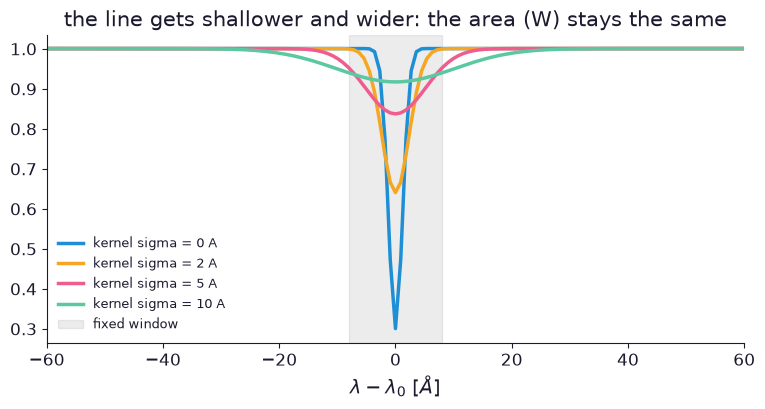

In [7]:
# Numerical check 1: an isolated Gaussian absorption line, broadened more and more
x = np.arange(-400, 401) * 0.9                  # wavelength offset [A], 0.9 A pixels like FaSTAR
line = 1 - 0.7 * np.exp(-0.5 * (x / 1.2) ** 2)  # depth 0.7, sigma 1.2 A
W_true = np.trapezoid(1 - line, x)

kernel_sigmas_A = [0.5, 2, 5, 10, 20]
for s_A in kernel_sigmas_A:
    broad = convolve(line, gaussian_kernel(s_A / 0.9))
    W_all = np.trapezoid(1 - broad, x)                            # whole line
    win = np.abs(x) < 8                                           # a fixed 16 A window
    W_win = np.trapezoid(1 - broad[win], x[win])
    print(f'kernel sigma {s_A:4.1f} A:  W (all) = {W_all:.3f} A,  W (16 A window) = {W_win:.3f} A,  true {W_true:.3f} A')

fig, ax = plt.subplots(figsize=(9, 4))
for s_A in [0, 2, 5, 10]:
    y = line if s_A == 0 else convolve(line, gaussian_kernel(s_A / 0.9))
    ax.plot(x, y, label=f'kernel sigma = {s_A} A')
ax.axvspan(-8, 8, color='grey', alpha=0.15, label='fixed window')
ax.set_xlim(-60, 60); ax.set_xlabel(r'$\lambda - \lambda_0$ [$\AA$]'); ax.legend(fontsize=9)
ax.set_title('the line gets shallower and wider: the area (W) stays the same')

In [8]:
# Numerical check 2: the real FaSTAR spectrum, Mg b region, broadened by velocity dispersion.
# W over a wide window (5100-5260 A) against a fixed continuum level stays (almost) the same;
# the Lick Mg b index in its fixed 32 A band drops.
def W_wide(lam_, f, lo=5100, hi=5260):
    sel = (lam_ > lo) & (lam_ < hi)
    cont = np.median(f[(lam_ > 5300) & (lam_ < 5330)])    # one continuum level for all
    return np.trapezoid(1 - f[sel] / cont, lam_[sel])

for sigma in [0, 100, 200, 300, 400]:
    b = broaden_velocity(spec_log, velscale, sigma)
    print(f'sigma = {sigma:3d} km/s:  W(5100-5260 A) = {W_wide(lam, b):6.2f} A,  Lick Mg b = {lick_index(lam, b, "Mgb"):5.2f} A')

sigma =   0 km/s:  W(5100-5260 A) =  21.90 A,  Lick Mg b =  3.70 A
sigma = 100 km/s:  W(5100-5260 A) =  21.89 A,  Lick Mg b =  3.74 A
sigma = 200 km/s:  W(5100-5260 A) =  20.82 A,  Lick Mg b =  3.58 A
sigma = 300 km/s:  W(5100-5260 A) =  20.19 A,  Lick Mg b =  3.22 A
sigma = 400 km/s:  W(5100-5260 A) =  20.21 A,  Lick Mg b =  2.83 A


**Questions.**
1. In check 2 the wide-window $W$ is conserved to a few per cent only. Which assumption of the proof is (slightly) violated? *(Hint: lines near the window edges; is the continuum flat?)*
2. Why do people still use fixed windows (Lick indices) if they are not conserved? *(Comparability between instruments/galaxies, and blends: a "whole line" does not exist in a crowded spectrum.)*
3. Show that convolving with a kernel of area 0.9 instead of 1 changes $W$. By how much — and why can a real LSF never do that?

## 6. Pixels and noise

A spectrum is sampled on pixels (Nyquist: at least ~2 pixels per FWHM) and every pixel has noise. Can you still see Hβ at S/N = 10?

Text(0.5, 0, 'wavelength [$\\AA$]')

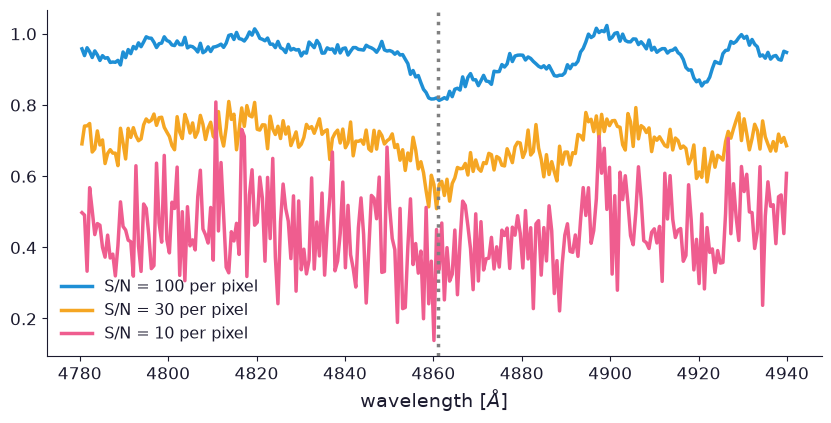

In [9]:
s200 = broaden_velocity(spec_log, velscale, 200)
fig, ax = plt.subplots(figsize=(10, 4.5))
sel = (lam > 4780) & (lam < 4940)
for i, snr in enumerate([100, 30, 10]):
    noisy, _ = add_noise(s200, snr, rng=i)
    ax.plot(lam[sel], noisy[sel] - 0.25 * i, label=f'S/N = {snr} per pixel')
ax.axvline(4861, color='grey', ls=':'); ax.legend(); ax.set_xlabel(r'wavelength [$\AA$]')

## Exercises

1. Degrade the spectrum to R = 100 (prism). Which features survive? Can you still tell a 1 Gyr from a 10 Gyr population (try `ssp.synthesize(age=1.0, met=0.0)`)?
2. Make Figure 4 for a young (0.5 Gyr) population. Does Hβ respond to σ in the same way?
3. Your spectrograph has FWHM = 3 Å, the models 2.51 Å, the galaxy σ = 60 km/s. What Gaussian do you convolve the *models* with before comparing them with the galaxy (give σ in km/s at 5000 Å)?
4. Use `scipy.ndimage.gaussian_filter1d` instead of `convolve(...)` and check you get the same answer.